In [9]:
import polars as pl
import glob
import numpy as np
import pandas as pd

import plotly.express as px
import matplotlib.pyplot as plt
import warnings

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances

warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
files = sorted(glob.glob('./data/EV__*.parquet'))

lf = pl.scan_parquet(files)
schema = lf.collect_schema()

lf.head(10).collect()

Time,[29:0]Schweißmaschine - Einspeisung L1 Strom Istwert,[29:1]Schweißmaschine - Einspeisung L2 Strom Istwert,[29:2]Schweißmaschine - Einspeisung L3 Strom Istwert,[29:3]Schweißmaschine - Einspeisung L1 Spannung Istwert,[29:4]Schweißmaschine - Einspeisung L2 Spannung Istwert,[29:5]Schweißmaschine - Einspeisung L3 Spannung Istwert,[29:6]Schweißmaschine - Schweißspannung Istwert,[29:7]Schweißmaschine - Schweißstrom Istwert,[68:0]Schweißstrom Differenz HKS - Shunt,[68_101]Schweißmaschine - (+NS01 & +NS02) Schweißen ein LM (A12_5),[68_120]Schweißmaschine - (SA) Geschweißt Relais (A15_0),[68_694]Schweißmaschine - Glaettrolle ist auf SBE (E37_6),[68_695]Schweißmaschine - Glaettrolle ist ab SE (E37_7),[72:0]MP377: Schweißstrom Sollwert (DB21_DBW646),[72:1]MP377: Schweißkraft Sollwert (DB21_DBW642),[72:2]MP377: Glättkraft Sollwert (DB21_DBW654),[72:3]MP377: Schweißgeschwindigkeit Sollwert (DB21_DBW644),[72:46]S7-Schweißmaschine - Antrieb C-Wagen Istposition in mm (DB40_DBD32),[72:47]S7-Schweißmaschine - Antrieb C-Wagen V-Ist in mm/s (DB40_DBD36),[72:54]Schweißstromregelung: Temperatur Stromschiene oben (DB510_DBD4),[72:61]Schweißstromregelung: Schweißstrom Sollwert skaliert (DB510_DBD8),[72:62]Schweißstromregelung: Temperatur Start Schweißen (DB510_DBD40),[72:67]Schweißstromregelung: Reglerausgang (DB510_DBD28),[72:68]Schweißstromregelung: Reglerdifferenz (DB510_DBD16),[72:69]Schweißstromregelung: Spannung am Shunt Rückführung (DB510_DBD48),[72:70]Schweißstrom_HKS Zuführung (DB550_DBD0),[72:71]Schweißspannung_HKS (DB550_DBD4),[72:72]Schweißstrom_HKS Rückführung (DB550_DBD24),[72:73]Glättdruckregelung: Druckistwert Glättrollen (100%=50KN) (DB520_DBD0),[72:74]Glättdruckregelung: Drucksollwert Glättrollen (100%=40KN) (DB520_DBD8),[72:75]Glättdruckregelung: Drucksollwert Glättrollen HLG (100%=40KN) (DB520_DBD12),[72:78]Glättdruckregelung: Reglerausgang (DB520_DBD28),[72:79]Glättdruckregelung: Reglerdifferenz (DB520_DBD16),[72:81]Glättdruckregelung: Reglerausgang Prop_-Ventil normiert (MW2416/PEW156),[72:99]S7-Schweißmaschine - Sollwert Schweißrollendruck an Druckregelventil (DB550_DBD20),[72:100]S7-Schweißmaschine - Istwert Schweißrollendruck vom Druckregelventil (DB550_DBD8),[72:101]S7-Schweißmaschine - Istwert Luftdruck am Schweißrollenzylinder (DB550_DBD12),[72:102]S7-Schweißmaschine - Istwert Luftdruck am Netz (DB550_DBD16),[72:103]S7-Schweißmaschine - Schweißstromregelung Grundsollwert vom Regler (DB22_DBD20),[72:104]S7-Schweißmaschine - Schweißstromregelung I-Anteil vom Regler (DB22_DBD24),[72:105]S7-Schweißmaschine - Schweißstromregelung P-Anteil vom Regler (DB22_DBD0),[72:159]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Sollwert (DB14_DBD4),[72:160]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Istwert (DB14_DBD8),[72:162]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Sollwert (DB14_DBD24),[72:163]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Istwert (DB14_DBD28),[72:165]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Sollwert (DB13_DBD4),[72:166]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Istwert (DB13_DBD8),[72:168]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Sollwert (DB14_DBD44),[72:169]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Istwert (DB14_DBD48),"[72:214]S7-Schweißmaschine - Dicke Band Auslauf (0,4mm-2,5mm = 40-250) (DB268_DBW56)",[72:215]S7-Schweißmaschine - Materialnummer Band Auslauf (1-5) (DB268_DBW58),[72:216]S7-Schweißmaschine - Breite Band Auslauf (120mm-2000mm) (DB268_DBW60),[72:217]S7-Schweißmaschine - Kohlenstoffgehalt Band Auslauf (DB268_DBD62),"[72:220]S7-Schweißmaschine - Dicke Band Einlauf (0,4mm-2,5mm = 40-250) (DB268_DBW76)",[72:221]S7-Schweißmaschine - Materialnummer Band Einlauf (1-5) (DB268_DBW78),[72:222]S7-Schweißmaschine - Breite Band Einlauf (120mm-2000mm) (DB268_DBW80),[72:223]S7-Schweißmaschine - Kohlenstoffgehalt Band Einlauf (DB268_DBD82),[72:226]S7-Schw

In [3]:
# keep only numerical columns for standartisation

EIN = "[72_1]S7-Schweißmaschine - Schweißen EIN (M215_0)"

features = [col for col, dtype in schema.items() if col not in ("Time", EIN) and dtype.is_numeric()]

df_features = lf.select("Time", EIN, *features).drop_nulls(subset=["Time", EIN])
df_features = df_features.with_columns(seq_id=(pl.col(EIN) & ~pl.col(EIN).shift(fill_value=False)).cum_sum() - 1)
df_features = df_features.filter(pl.col(EIN)).select("Time", "seq_id", *features)

df_features.slice(18190, 10).collect(engine="streaming")

Time,seq_id,[29:0]Schweißmaschine - Einspeisung L1 Strom Istwert,[29:1]Schweißmaschine - Einspeisung L2 Strom Istwert,[29:2]Schweißmaschine - Einspeisung L3 Strom Istwert,[29:3]Schweißmaschine - Einspeisung L1 Spannung Istwert,[29:4]Schweißmaschine - Einspeisung L2 Spannung Istwert,[29:5]Schweißmaschine - Einspeisung L3 Spannung Istwert,[29:6]Schweißmaschine - Schweißspannung Istwert,[29:7]Schweißmaschine - Schweißstrom Istwert,[68:0]Schweißstrom Differenz HKS - Shunt,[72:0]MP377: Schweißstrom Sollwert (DB21_DBW646),[72:1]MP377: Schweißkraft Sollwert (DB21_DBW642),[72:2]MP377: Glättkraft Sollwert (DB21_DBW654),[72:3]MP377: Schweißgeschwindigkeit Sollwert (DB21_DBW644),[72:46]S7-Schweißmaschine - Antrieb C-Wagen Istposition in mm (DB40_DBD32),[72:47]S7-Schweißmaschine - Antrieb C-Wagen V-Ist in mm/s (DB40_DBD36),[72:54]Schweißstromregelung: Temperatur Stromschiene oben (DB510_DBD4),[72:61]Schweißstromregelung: Schweißstrom Sollwert skaliert (DB510_DBD8),[72:62]Schweißstromregelung: Temperatur Start Schweißen (DB510_DBD40),[72:67]Schweißstromregelung: Reglerausgang (DB510_DBD28),[72:68]Schweißstromregelung: Reglerdifferenz (DB510_DBD16),[72:69]Schweißstromregelung: Spannung am Shunt Rückführung (DB510_DBD48),[72:70]Schweißstrom_HKS Zuführung (DB550_DBD0),[72:71]Schweißspannung_HKS (DB550_DBD4),[72:72]Schweißstrom_HKS Rückführung (DB550_DBD24),[72:73]Glättdruckregelung: Druckistwert Glättrollen (100%=50KN) (DB520_DBD0),[72:74]Glättdruckregelung: Drucksollwert Glättrollen (100%=40KN) (DB520_DBD8),[72:75]Glättdruckregelung: Drucksollwert Glättrollen HLG (100%=40KN) (DB520_DBD12),[72:78]Glättdruckregelung: Reglerausgang (DB520_DBD28),[72:79]Glättdruckregelung: Reglerdifferenz (DB520_DBD16),[72:81]Glättdruckregelung: Reglerausgang Prop_-Ventil normiert (MW2416/PEW156),[72:99]S7-Schweißmaschine - Sollwert Schweißrollendruck an Druckregelventil (DB550_DBD20),[72:100]S7-Schweißmaschine - Istwert Schweißrollendruck vom Druckregelventil (DB550_DBD8),[72:101]S7-Schweißmaschine - Istwert Luftdruck am Schweißrollenzylinder (DB550_DBD12),[72:102]S7-Schweißmaschine - Istwert Luftdruck am Netz (DB550_DBD16),[72:103]S7-Schweißmaschine - Schweißstromregelung Grundsollwert vom Regler (DB22_DBD20),[72:104]S7-Schweißmaschine - Schweißstromregelung I-Anteil vom Regler (DB22_DBD24),[72:105]S7-Schweißmaschine - Schweißstromregelung P-Anteil vom Regler (DB22_DBD0),[72:159]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Sollwert (DB14_DBD4),[72:160]S7-Schweißmaschine - Tischverstellung Überlapptisch Ausspannlänge Istwert (DB14_DBD8),[72:162]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Sollwert (DB14_DBD24),[72:163]S7-Schweißmaschine - Tischverstellung Überlapptisch Überlappung Istwert (DB14_DBD28),[72:165]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Sollwert (DB13_DBD4),[72:166]S7-Schweißmaschine - Tischverstellung Kipptisch Ausspannlänge Istwert (DB13_DBD8),[72:168]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Sollwert (DB14_DBD44),[72:169]S7-Schweißmaschine - Tischverstellung Überlapptisch Schränkung Istwert (DB14_DBD48),"[72:214]S7-Schweißmaschine - Dicke Band Auslauf (0,4mm-2,5mm = 40-250) (DB268_DBW56)",[72:215]S7-Schweißmaschine - Materialnummer Band Auslauf (1-5) (DB268_DBW58),[72:216]S7-Schweißmaschine - Breite Band Auslauf (120mm-2000mm) (DB268_DBW60),[72:217]S7-Schweißmaschine - Kohlenstoffgehalt Band Auslauf (DB268_DBD62),"[72:220]S7-Schweißmaschine - Dicke Band Einlauf (0,4mm-2,5mm = 40-250) (DB268_DBW76)",[72:221]S7-Schweißmaschine - Materialnummer Band Einlauf (1-5) (DB268_DBW78),[72:222]S7-Schweißmaschine - Breite Band Einlauf (120mm-2000mm) (DB268_DBW80),[72:223]S7-Schweißmaschine - Kohlenstoffgehalt Band Einlauf (DB268_DBD82),[72:226]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Kolbenseite (DB9_DBD60),[72:227]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Flächenseite (DB9_DBD64)
datetime[ms],u32,f32,f32,f32,f32,f32,f32,f32,f32,

In [31]:
# Für jedes Feature den Mittelwert and die Standartabweichung berechnen
means = df_features.select([pl.col(col).mean().alias(col) for col in features]).collect(engine="streaming")
stds = df_features.select([pl.col(col).std().alias(col) for col in features]).collect(engine="streaming")

# polars-dataFrame --> numpy-array
means = np.array([means[col][0] for col in features])
stds = np.array([stds[col][0] for col in features])

means_np = np.asarray(means, dtype=np.float64)
stds_np = np.asarray(stds, dtype=np.float64)

summary = pl.DataFrame({
    "feature": features,
    "mean": means_np,
    "std": stds_np
})

# Features finden, deren Standardabweichung 0
# solche Features sind konstant und enthalten keine Variationen
const_features = (
    summary
    .filter(pl.col("std") == 0)
    .get_column("feature")
    .to_list()
    
)

# kosntante Features entfernen
features = [col for col in features if col not in const_features]

# Features erneut auswählen
# dabei werden nur nicht-konstante Features verwendet
df_features = lf.select("Time", EIN, *features).drop_nulls(subset=["Time", EIN])
df_features = df_features.with_columns(seq_id=(pl.col(EIN) & ~pl.col(EIN).shift(fill_value=False)).cum_sum() - 1)
df_features = df_features.filter(pl.col(EIN)).select("Time", "seq_id", *features)

In [71]:
df_seq = (
    df_features
    .group_by("seq_id")
    .agg(start=pl.col("Time").min(), end=pl.col("Time").max())
    .sort("seq_id")
    .collect(engine="streaming")
)

def interpolate(N):
    """Lineare Interpolation jeder Schweißsequenz auf N Zeitpunkte"""

    # Matrix für alle Sequenzen und interpolierten Features erstellen
    # Zeile entspricht einer Schweißsequenz
    # dabei IDs der Schweißsequenzen speichern
    X = np.empty((len(df_seq), len(features) * N), dtype=np.float64)
    seq_ids = df_seq["seq_id"].to_list()

    # Features standardisieren
    norm = [((pl.col(col) - mean) / std).cast(pl.Float64).alias(col) for col, mean, std in zip(features, means_np, stds_np)]

    empty = []

    for i, row in enumerate(df_seq.iter_rows(named=True)):
        seq = lf.filter(pl.col("Time").is_between(row["start"], row["end"]))
        seq = seq.filter(pl.col(EIN))
        seq = seq.select("Time", *features)
        seq = seq.sort("Time")
        seq = seq.with_columns(norm)
        seq = seq.collect(engine="streaming")

        t = (seq["Time"] - seq["Time"][0]).dt.total_milliseconds().to_numpy()
        t_lin = np.linspace(0, t[-1], N)
        

        for j, feature in enumerate(features):
            y = seq[feature].to_numpy()
            
            # Maske für NAN-Werte
            # Prüfen ob Feature Messwerte enthält
            dummy = ~np.isnan(y)
            if not dummy.any():
                empty.append((row["seq_id"], feature))
                X[i, j*N:(j+1)*N] = 0.0
                continue
            X[i, j*N:(j+1)*N] = np.interp(t_lin, t[dummy], y[dummy])
    return X, seq_ids, empty

def build_df_X(N):
    X, seq_ids, _ = interpolate(N)

    cols = [
        f"{feature}_t_{i}"
        for feature in features
        for i in range(N)
    ]

    return pd.DataFrame(
        X,
        index=pd.Index(seq_ids, name="seq_id"),
        columns=cols,
    )

In [72]:
N_SAMPLES = 300

df_X = build_df_X(N_SAMPLES)
X = df_X.to_numpy()
df_X.iloc[:10, ::N_SAMPLES]

,[29:0]Schweißmaschine - Einspeisung L1 Strom Istwert_t_0,[29:1]Schweißmaschine - Einspeisung L2 Strom Istwert_t_0,[29:2]Schweißmaschine - Einspeisung L3 Strom Istwert_t_0,[29:3]Schweißmaschine - Einspeisung L1 Spannung Istwert_t_0,[29:4]Schweißmaschine - Einspeisung L2 Spannung Istwert_t_0,[29:5]Schweißmaschine - Einspeisung L3 Spannung Istwert_t_0,[29:6]Schweißmaschine - Schweißspannung Istwert_t_0,[29:7]Schweißmaschine - Schweißstrom Istwert_t_0,[68:0]Schweißstrom Differenz HKS - Shunt_t_0,[72:0]MP377: Schweißstrom Sollwert (DB21_DBW646)_t_0,...,"[72:214]S7-Schweißmaschine - Dicke Band Auslauf (0,4mm-2,5mm = 40-250) (DB268_DBW56)_t_0",[72:215]S7-Schweißmaschine - Materialnummer Band Auslauf (1-5) (DB268_DBW58)_t_0,[72:216]S7-Schweißmaschine - Breite Band Auslauf (120mm-2000mm) (DB268_DBW60)_t_0,[72:217]S7-Schweißmaschine - Kohlenstoffgehalt Band Auslauf (DB268_DBD62)_t_0,"[72:220]S7-Schweißmaschine - Dicke Band Einlauf (0,4mm-2,5mm = 40-250) (DB268_DBW76)_t_0",[72:221]S7-Schweißmaschine - Materialnummer Band Einlauf (1-5) (DB268_DBW78)_t_0,[72:222]S7-Schweißmaschine - Breite Band Einlauf (120mm-2000mm) (DB268_DBW80)_t_0,[72:223]S7-Schweißmaschine - Kohlenstoffgehalt Band Einlauf (DB268_DBD82)_t_0,[72:226]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Kolbenseite (DB9_DBD60)_t_0,[72:227]S7-Schweißmaschine - Druckmessung Überlapptisch Hydraulikzylinder Flächenseite (DB9_DBD64)_t_0
seq_id,,,,,,,,,,,,,,,,,,,,,
0,-1.297148,-1.268423,-1.268564,1.229979,1.184601,-0.035332,-1.096739,-1.284923,0.337652,-0.402192,...,-0.864620,1.992485,0.647726,-0.568662,-0.923870,-1.366042,-0.335156,0.458539,1.023532,2.539021
1,-1.289318,-1.268423,-1.268564,0.616856,1.376098,0.737376,-1.095343,-1.283809,0.342114,-1.210720,...,-0.949266,-1.328208,-0.331980,0.483010,-0.923870,-1.366042,-0.347407,0.458539,0.942850,1.303295
2,-1.281487,-1.268423,-1.268564,-0.173731,-1.303707,-1.130994,-1.093947,-1.279351,0.340260,-1.095216,...,-0.949266,-1.328208,-0.345043,0.483010,-0.854382,-1.366042,-1.078370,0.414097,0.942850,1.303295
3,-1.289318,-1.268423,-1.268564,1.264312,1.182075,-0.065774,-1.095343,-1.282694,0.342139,-1.095216,...,-0.878727,-1.328208,-1.124454,0.437285,-0.923870,0.422324,-1.482646,-0.563642,-0.106099,2.539021
4,-1.285403,-1.268423,-1.268564,-1.347086,-0.256905,1.066051,-1.092551,-1.281580,0.339785,-1.210720,...,-0.949266,0.332139,-1.555525,-0.568662,-0.923870,0.422324,-1.482646,-0.519199,0.135969,7.481921
5,-1.285403,-1.268423,-1.262809,0.225738,1.320532,1.097408,-1.091155,-1.283251,0.347560,-1.210720,...,-0.949266,0.332139,-1.555525,-0.522937,-0.923870,0.422324,-1.482646,-0.563642,3.040733,0.067570
6,-1.281487,-1.268423,-1.262809,-0.515902,0.893223,1.400220,-1.089061,-1.281023,0.346579,-1.210720,...,-0.949266,0.332139,-1.555525,-0.568662,-0.923870,0.422324,-1.482646,-0.563642,3.040733,1.303295
7,-1.289318,-1.268423,-1.262809,0.493211,1.388497,0.888210,-1.091853,-1.282137,0.342165,-1.210720,...,-0.949266,0.332139,-1.555525,-0.568662,-0.937768,0.422324,-1.482646,-0.563642,1.265593,1.303295
8,-1.281487,-1.268423,-1.262809,1.408372,0.369937,-0.996868,-1.093947,-1.279908,0.338049,-1.210720,...,-0.963374,0.332139,-1.555525,-0.568662,-0.923870,0.422324,-1.482646,-0.563642,0.700781,1.303295


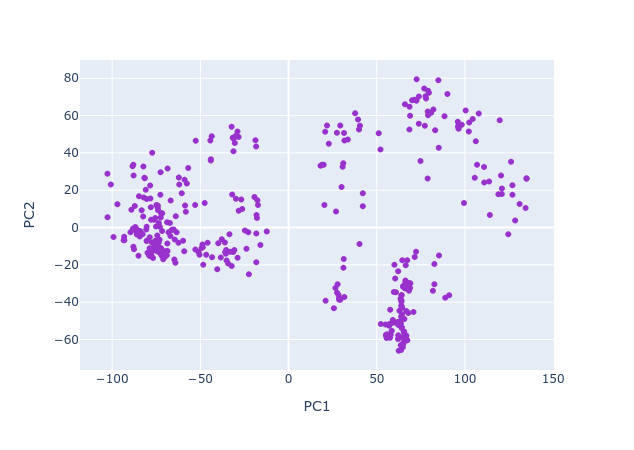

In [34]:
# PCA für 2 Hauptkomponenten
pca2 = PCA(n_components=2)

# # Projektion auf die Hauptkomponenten
df_pca = pd.DataFrame(pca2.fit_transform(X), columns=["PC1", "PC2"], index=df_X.index)

fig = px.scatter(df_pca, x="PC1", y="PC2", hover_name=df_pca.index, width=750, height=450)
fig.update_traces(marker=dict(color="darkorchid"))
fig.show()

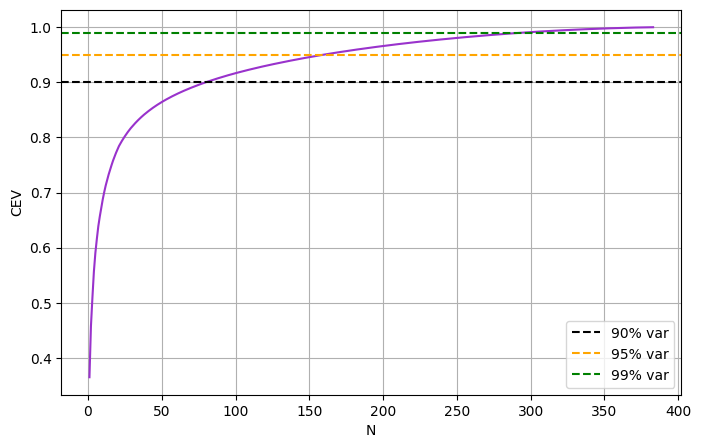

In [35]:
PCA_ = PCA()
PCA_.fit(X)

# Cumulative Explained Variance Ratio berechnen 
cum_var = PCA_.explained_variance_ratio_.cumsum()

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, color="darkorchid")

plt.axhline(y=0.9, linestyle="--", label="90% var", color="black")
plt.axhline(y=0.95, linestyle="--", label="95% var", color="orange")
plt.axhline(y=0.99, linestyle="--", label="99% var", color="green")
plt.xlabel("N")
plt.ylabel("CEV")
plt.grid(True)
plt.legend()
plt.show()

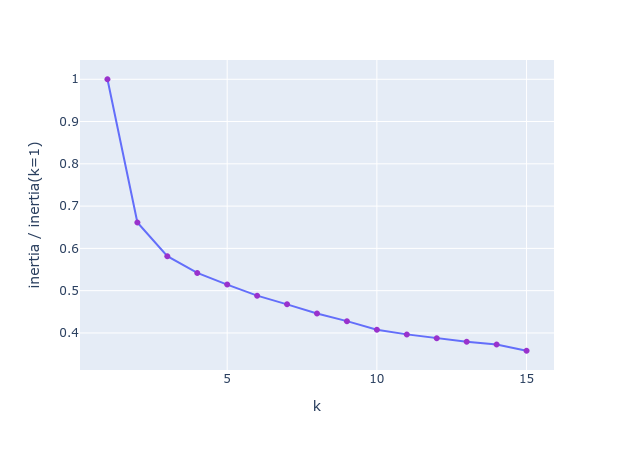

In [36]:
var = PCA_.explained_variance_ratio_

# Anzahl der Hauptkomponenten bestimmen, die mindestens 95 % der Gesamtvarianz haben
total = 0
n = 0

for v in var:
    total += v
    n += 1

    if  total >= 0.95:
        break
        
X_PCA = PCA_.transform(X)
# Nur die ersten n Hauptkomponenten für die Clustering
X_reduced = X_PCA[:, :n]

# Elbow-Methode zur Bestimmung einer geeigneten Clusteranzahl
def elbow(n_init=10, k_max=15, data=X_reduced):
    ks = np.arange(1,k_max+1)
    inertias = [KMeans(n_clusters=k, n_init=n_init, random_state=0).fit(data).inertia_ for k in ks]
    
    return ks, inertias

ks, inertias = elbow(n_init=50)
ret = np.array(inertias) / inertias[0]

# Visualisierung der Elbow-Methode
fig = px.line(x=ks, y=ret, markers=True, labels={"x": "k", "y": "inertia / inertia(k=1)"}, width=800, height=450)
fig.update_traces(marker=dict(color="darkorchid"))
fig.show()

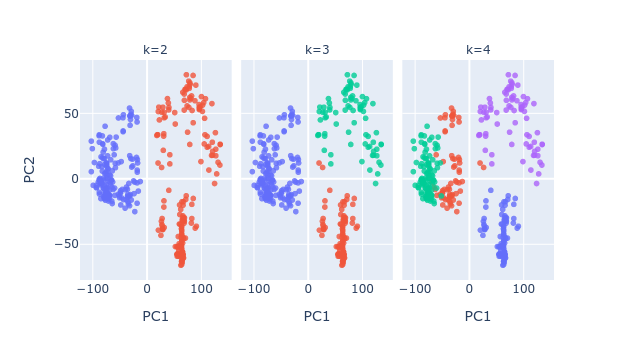

In [38]:
containers = []

# Clustering
for k in [2, 3, 4]:
    tmp = df_pca[["PC1", "PC2"]].copy()
    # K-Means-Clustering mit k Clustern durchführen
    # n_init=50: 50 unterschiedlichen Initialisierungen ausführen
    tmp["cluster"] = KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X_reduced).astype(str)
    tmp["k"] = k
    containers.append(tmp)

main_container = pd.concat(containers)

fig = px.scatter(main_container, x="PC1", y="PC2", color="cluster", facet_col="k", hover_name=main_container.index)
fig.update_traces(marker=dict(size=6, opacity=0.8))
fig.update_layout(showlegend=False)
fig.show()

In [39]:
# Zwei Sequenzen finden, die im PCA-Raum am nächsten beieinander liegen
def find_nearest_points(df):
    P = df[["PC1", "PC2"]].to_numpy()
    # Paarweise euklidische Abstände zwischen allen Punkten berechnen
    dist = pairwise_distances(P)
    # Selbstabstände ausschließen
    np.fill_diagonal(dist, np.inf)
    # Indzes bestimmen
    i, j = np.unravel_index(dist.argmin(), dist.shape)

    return df.index[i], df.index[j]

# Zwei Sequenzen finden, die im PCA-Raum am weitesten voneinander entfernt liegen
def find_farthest_points(df):
    P = df[["PC1", "PC2"]].to_numpy()
    dist = pairwise_distances(P)
    np.fill_diagonal(dist, -np.inf)
    i, j = np.unravel_index(dist.argmax(), dist.shape)

    return df.index[i], df.index[j]

def find_outlier(df, k=5):
    P = df[["PC1", "PC2"]].to_numpy()

    # K-nearest Algorithm
    nn = NearestNeighbors(n_neighbors=k).fit(P)
    dist, idx = nn.kneighbors(P)
    
    # Die erste Spalte enthält den Punkt selbs
    # Deshalb nur die Abstände zu den Nachbarn berechnen
    mean_dist = dist[:, 1:].mean(axis=1)

    # Punkt mit dem größten mittleren Nachbarabstand auswählen
    i = mean_dist.argmax()
    # Den nächsten Nachbarn bestimmen
    j = idx[i, 1]

    return df.index[i], df.index[j]

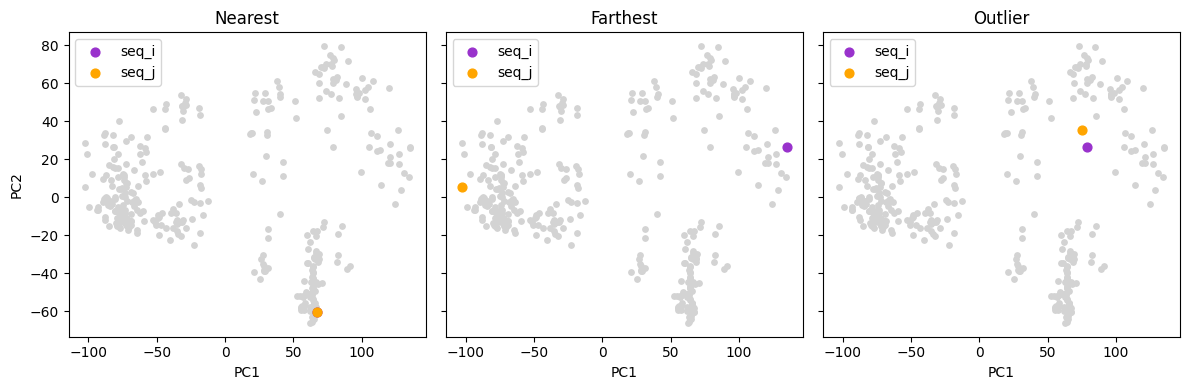

In [42]:
pairs = {
    "Nearest": find_nearest_points(df_pca),
    "Farthest": find_farthest_points(df_pca),
    "Outlier": find_outlier(df_pca),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)

for ax, (name, (i, j)) in zip(axes, pairs.items()):
    ax.scatter(df_pca["PC1"], df_pca["PC2"],color="lightgray", s=15)
    ax.scatter(df_pca.loc[i, "PC1"], df_pca.loc[i, "PC2"], color="darkorchid", s=40, label="seq_i",)
    ax.scatter(df_pca.loc[j, "PC1"], df_pca.loc[j, "PC2"], color="orange", s=40, label="seq_j",)

    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.legend()

axes[0].set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [77]:
def get_orig_seq(seq_id):
    row = df_seq.filter(pl.col("seq_id") == seq_id).row(0, named=True)

    seq = lf.filter(pl.col("Time").is_between(row["start"], row["end"]))
    seq = seq.filter(pl.col(EIN))
    seq = seq.select("Time", *features)
    seq = seq.sort("Time")
    seq = seq.collect(engine="streaming")

    return seq


def get_interp_seq(seq_id):
    return df_X.loc[seq_id]


def plot_orig_and_interp_seq(seq_i, seq_j, interp_i, interp_j, i, j, feature):
    """"""
    cols = [f"{feature}_t_{k}" for k in range(N_SAMPLES)]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))

    for seq, interp, seq_id, color in [(seq_i, interp_i, i, "darkorchid"),(seq_j, interp_j, j, "orange"),]:
        t = (seq["Time"] - seq["Time"][0]).dt.total_milliseconds().to_numpy()
        ax1.plot(t, seq[feature].to_numpy(), color=color, label=f"seq_id={seq_id}") # orig
        ax2.plot(np.arange(N_SAMPLES), interp[cols].to_numpy(), color=color, label=f"seq_id={seq_id}") # interp

    ax1.set_title("Orig")
    ax1.set_ylabel(feature)
    ax1.legend()
    ax1.grid(alpha=0.6)

    ax2.set_title("Interp.")
    ax2.set_xlabel("t")
    ax2.legend()
    ax2.grid(alpha=0.6)

    plt.tight_layout()
    plt.show()

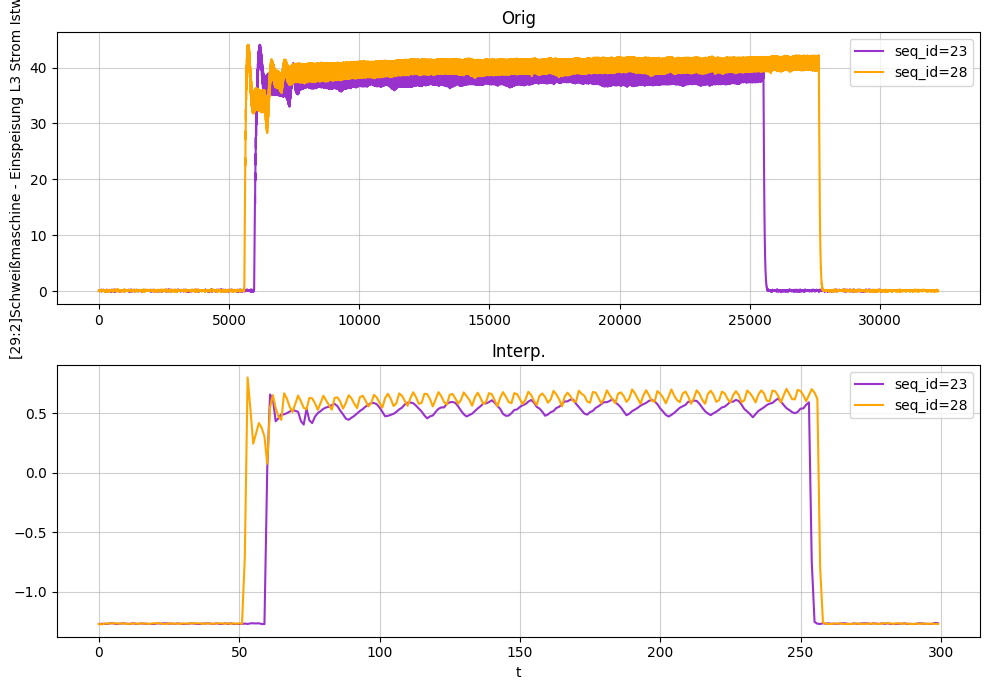

In [78]:
i, j = pairs["Nearest"]
plot_orig_and_interp_seq(get_orig_seq(i), get_orig_seq(j), get_interp_seq(i), get_interp_seq(j), i, j, features[2])

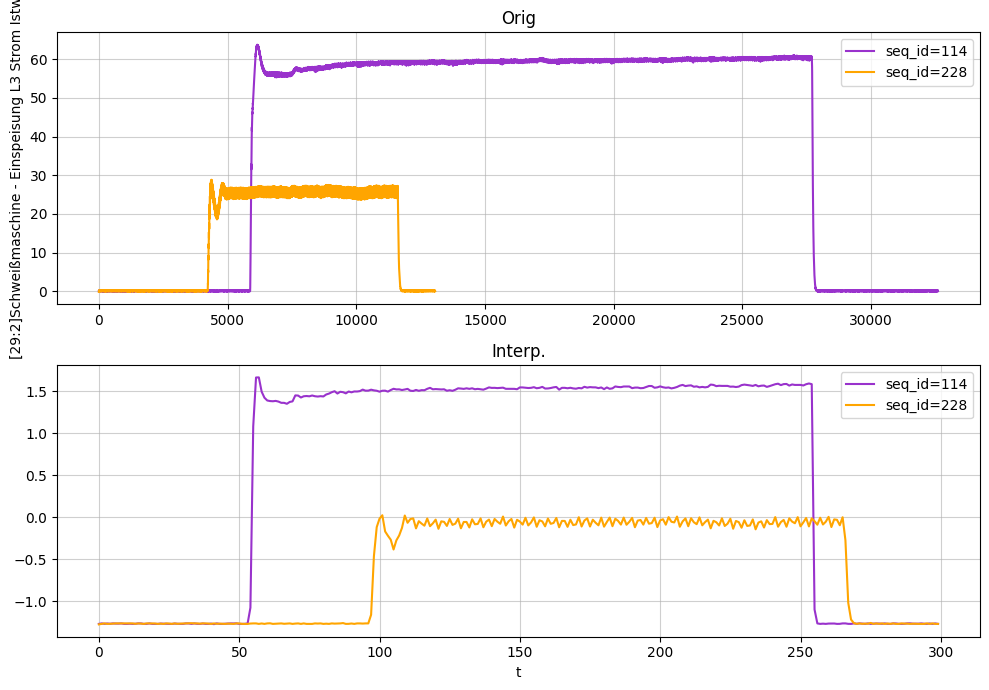

In [79]:
i, j = pairs["Farthest"]
plot_orig_and_interp_seq(get_orig_seq(i), get_orig_seq(j), get_interp_seq(i), get_interp_seq(j), i, j, features[2])

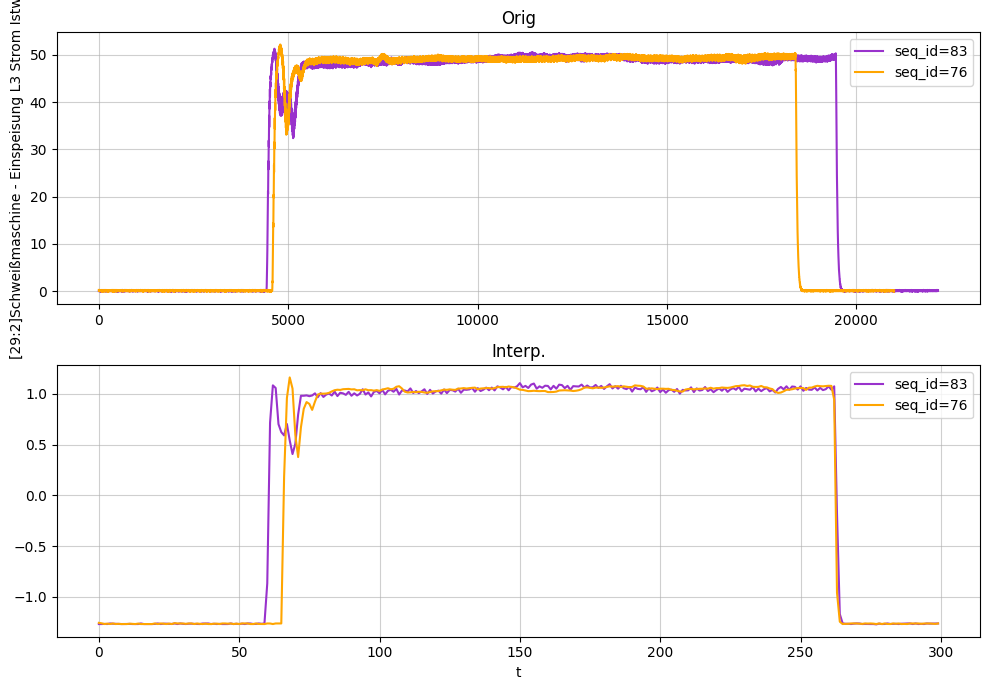

In [80]:
i, j = pairs["Outlier"]
plot_orig_and_interp_seq(get_orig_seq(i), get_orig_seq(j), get_interp_seq(i), get_interp_seq(j), i, j, features[2])